[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_density_var/BA_L4_density_var.ipynb)

# BA_L4_density_var: VaR and ES on the Bitcoin forecast density

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

GARCH(1,1)-t forecast density of the Bitcoin return on 19 September 2026 against a Normal density with the same mean and standard deviation, with the VaR 1% and ES 2.5% of each; the level at which the two VaRs cross.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Model.** $r_t = \mu + \varepsilon_t$, $\varepsilon_t = \sigma_t z_t$, with the GARCH(1,1) recursion of Bollerslev (1986)
$$ \sigma_t^2 = \omega + \alpha\,\varepsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2 , $$
and $z_t$ i.i.d. (independent and identically distributed) Student-t with $\nu$ degrees of freedom, rescaled to variance 1 (GARCH-t).
$\alpha + \beta$ is the persistence; the parameters are estimated by maximum likelihood.

**Data.** Bitcoin daily log returns in per cent (EODHD), 1 January 2018 – 18 September 2026.

**Method.** One-step forecast $\hat\sigma_{t+1}$ for 19 September 2026. With $q = t_\nu^{-1}(p)$ and $s = \sqrt{(\nu-2)/\nu}$: $\mathrm{VaR}_p = -(\hat\mu + \hat\sigma_{t+1} s q)$ and $\mathrm{ES}_p = -\hat\mu + \hat\sigma_{t+1} s \frac{f_\nu(q)}{p}\frac{\nu + q^2}{\nu - 1}$; the Normal uses $\Phi^{-1}(p)$ and $\varphi(\Phi^{-1}(p))/p$ with the same $\hat\mu$ and $\hat\sigma_{t+1}$.

**How to read.** Left: the two densities. Right: the left tail; solid lines $-\mathrm{VaR}_{1\%}$, dotted lines $-\mathrm{ES}_{2.5\%}$; orange GARCH-t, blue Normal.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]


R = {k: log_returns(ASSETS[k][0]) for k in ['Bitcoin']}
print({k: f'{len(r)} days, {r.index[0].date()} - {r.index[-1].date()}' for k, r in R.items()})

{'Bitcoin': '3183 days, 2018-01-01 - 2026-09-18'}


In [6]:
# GARCH(1,1) with Student-t errors, estimated by maximum likelihood (package arch)
fits = {k: arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off') for k, r in R.items()}
pd.DataFrame({k: {'mu': g.params['mu'], 'omega': g.params['omega'], 'alpha': g.params['alpha[1]'], 'beta': g.params['beta[1]'],
                   'alpha + beta': g.params['alpha[1]'] + g.params['beta[1]'], 'nu': g.params['nu']} for k, g in fits.items()}).round(4)

,Bitcoin
mu,0.0563
omega,0.1442
alpha,0.0761
beta,0.9239
alpha + beta,1.0000
nu,3.1260


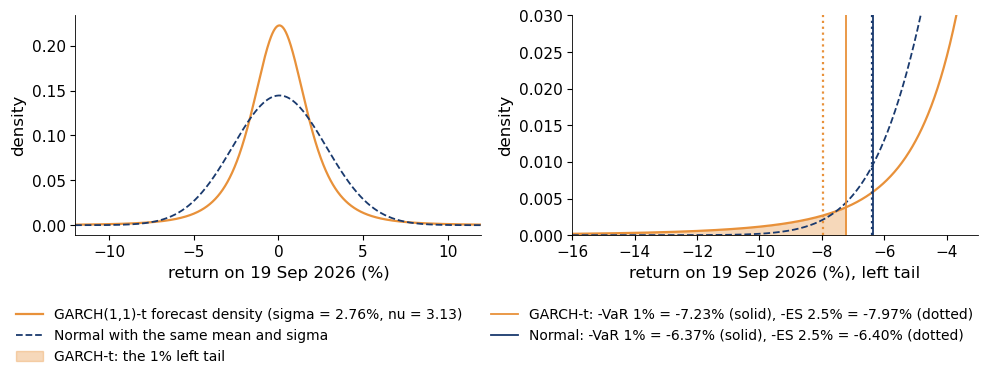

In [7]:
p1, p25 = 0.01, 0.025
z1, z25 = stats.norm.ppf(p1), stats.norm.ppf(p25)


def es_factor(q, p, nu):
    # f_nu(q) / p * (nu + q^2) / (nu - 1): the ES multiplier of the standard Student-t
    return stats.t.pdf(q, nu) / p * (nu + q ** 2) / (nu - 1)

gb_ = fits['Bitcoin']; nu_d, mu_d = gb_.params['nu'], gb_.params['mu']; sc_d = np.sqrt((nu_d - 2) / nu_d)
sf_d = np.sqrt(gb_.forecast(horizon=1, reindex=False).variance.values[-1, 0])
tq1_d, tq25_d = stats.t.ppf(p1, nu_d), stats.t.ppf(p25, nu_d)
var_t, es_t = -(mu_d + sf_d * sc_d * tq1_d), -mu_d + sf_d * sc_d * es_factor(tq25_d, p25, nu_d)
var_n, es_n = -(mu_d + sf_d * z1), -mu_d + sf_d * stats.norm.pdf(z25) / p25
xg = np.linspace(-16, 12, 1401)
ft = stats.t.pdf((xg - mu_d) / (sf_d * sc_d), nu_d) / (sf_d * sc_d); fn = stats.norm.pdf((xg - mu_d) / sf_d) / sf_d
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(xg, ft, color=BTC, lw=1.6, label=f'GARCH(1,1)-t forecast density (sigma = {sf_d:.2f}%, nu = {nu_d:.2f})')
ax[0].plot(xg, fn, color=BLUE, lw=1.3, ls='--', label='Normal with the same mean and sigma')
ax[0].set_xlim(-12, 12); ax[0].set_xlabel('return on 19 Sep 2026 (%)'); ax[0].set_ylabel('density')
ax[1].plot(xg, ft, color=BTC, lw=1.6); ax[1].plot(xg, fn, color=BLUE, lw=1.3, ls='--')
ax[1].fill_between(xg[xg <= -var_t], 0, ft[xg <= -var_t], color=BTC, alpha=0.35, label='GARCH-t: the 1% left tail')
ax[1].axvline(-var_t, color=BTC, lw=1.3, label=f'GARCH-t: -VaR 1% = {-var_t:.2f}% (solid), -ES 2.5% = {-es_t:.2f}% (dotted)')
ax[1].axvline(-es_t, color=BTC, ls=':', lw=1.6)
ax[1].axvline(-var_n, color=BLUE, lw=1.3, label=f'Normal: -VaR 1% = {-var_n:.2f}% (solid), -ES 2.5% = {-es_n:.2f}% (dotted)')
ax[1].axvline(-es_n, color=BLUE, ls=':', lw=1.6)
ax[1].set_xlim(-16, -3); ax[1].set_ylim(0, 0.03); ax[1].set_xlabel('return on 19 Sep 2026 (%), left tail'); ax[1].set_ylabel('density')
legend_below(fig, ncol=2); fig.tight_layout(rect=(0, 0.2, 1, 1))
save_fig(fig, 'ba_l4_density_var')

**Key numbers** (as on the slide).

In [8]:
from scipy.optimize import brentq
p_cross = brentq(lambda p_: sc_d * stats.t.ppf(p_, nu_d) - stats.norm.ppf(p_), 0.005, 0.2)
pd.Series({'sigma_(t+1) (% a day)': sf_d, 'nu': nu_d, 'VaR 1%, Student-t (%)': var_t, 'VaR 1%, Normal (%)': var_n,
           'ES 2.5%, Student-t (%)': es_t, 'ES 2.5%, Normal (%)': es_n,
           'P(loss > Normal VaR 1%) under the Student-t (%)': 100 * stats.t.cdf((-var_n - mu_d) / (sf_d * sc_d), nu_d),
           'level p where the two VaRs cross (%)': 100 * p_cross,
           'VaR 5%, Normal (%)': -(mu_d + sf_d * stats.norm.ppf(0.05)), 'VaR 5%, Student-t (%)': -(mu_d + sf_d * sc_d * stats.t.ppf(0.05, nu_d))}).round(3).to_frame('value')

,value
sigma_(t+1) (% a day),2.761
nu,3.126
"VaR 1%, Student-t (%)",7.231
"VaR 1%, Normal (%)",6.367
"ES 2.5%, Student-t (%)",7.971
"ES 2.5%, Normal (%)",6.398
P(loss > Normal VaR 1%) under the Student-t (%),1.412
level p where the two VaRs cross (%),1.921
"VaR 5%, Normal (%)",4.485
"VaR 5%, Student-t (%)",3.780
